# Industrial IoT Predictive Maintenance Pipeline

## Project Objective
This project implements an end-to-end machine learning pipeline to predict equipment failures in an industrial manufacturing line using IoT sensor telemetry. The goal is to accurately classify machine states ($0 = \text{Healthy}, 1 = \text{Faulty}$) based on physical sensor metrics, helping minimize unexpected downtime.

## Dataset Features
- **vibration**: Mechanical oscillations indicating wear or imbalance.
- **acoustic**: Sound emissions related to operation.
- **temperature**: Operational heat levels in °C.
- **current**: Electrical current draw in amps.
- **IMF_1, IMF_2, IMF_3**: Decomposed signal components representing underlying patterns.
- **machine_id**: Production line unit identifier (`M01`, `M02`, `M03`).
- **label**: Target failure state binary flag.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

Maint = pd.read_csv("predictive_maintenance_dataset.csv")
Maint.head()

,timestamp,machine_id,vibration,acoustic,temperature,current,IMF_1,IMF_2,IMF_3,label
0,2024-07-01 08:00:00,M01,0.822,0.645,66.85,13.04,0.196,0.033,0.000,0
1,2024-07-01 08:01:00,M01,1.398,0.834,76.20,15.08,0.345,0.132,0.001,1
2,2024-07-01 08:02:00,M01,0.856,0.590,67.03,12.30,0.187,0.017,0.002,0
3,2024-07-01 08:03:00,M01,0.793,0.544,65.04,11.69,0.196,-0.060,0.003,0
4,2024-07-01 08:04:00,M01,1.279,0.721,78.19,14.84,0.330,-0.115,0.004,1


In [20]:
Maint.describe().round(2)

,vibration,acoustic,temperature,current,IMF_1,IMF_2,IMF_3,label
count,1800.00,1800.00,1800.00,1800.00,1800.00,1800.00,1800.00,1800.00
mean,0.84,0.63,66.36,12.33,0.17,0.00,0.00,0.11
std,0.14,0.11,4.45,1.09,0.06,0.07,0.04,0.32
min,0.64,0.43,58.36,10.29,0.07,-0.18,-0.05,0.00
25%,0.77,0.57,63.73,11.70,0.12,-0.06,-0.04,0.00
50%,0.80,0.61,65.35,12.08,0.17,-0.00,0.00,0.00
75%,0.85,0.65,66.99,12.48,0.21,0.06,0.04,0.00
max,1.40,1.08,85.16,16.94,0.39,0.19,0.05,1.00


## Exploratory Data Analysis: Sensor Correlation Heatmap
Before modeling, we evaluate linear relationships between sensors. This helps visualize how the features correlate with system failures and between each other.

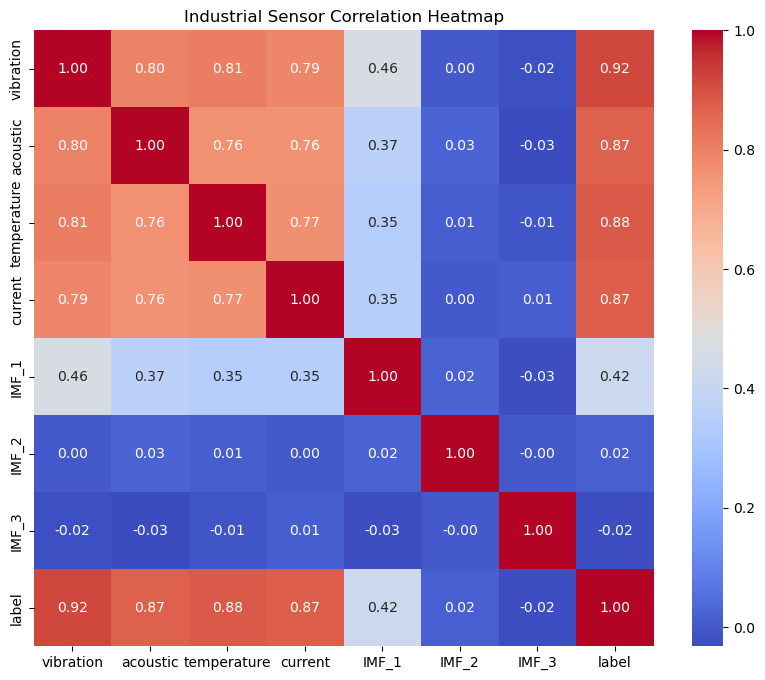

In [21]:
numeric_df = Maint.drop(['timestamp', 'machine_id'], axis=1)
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Industrial Sensor Correlation Heatmap')
plt.show()

## Data Preprocessing & Feature Engineering
1. **Datetime Parsing:** Convert timestamps to hour and minute features to enable the random forest to properly account for them.
2. **One-Hot Encoding:** Convert categorical `machine_id` strings (`M01`, `M02`, `M03`) into binary indicator columns. We use `drop_first=True` to prevent multicollinearity 

In [22]:
Maint['timestamp'] = pd.to_datetime(Maint['timestamp'])

Maint['hour'] = Maint['timestamp'].dt.hour
Maint['minute'] = Maint['timestamp'].dt.minute

Maint = Maint.drop('timestamp', axis=1)

Maint_encoded = pd.get_dummies(Maint, columns=['machine_id'], drop_first=True)

Maint_encoded.head()

,vibration,acoustic,temperature,current,IMF_1,IMF_2,IMF_3,label,hour,minute,machine_id_M02,machine_id_M03
0,0.822,0.645,66.85,13.04,0.196,0.033,0.000,0,8,0,False,False
1,1.398,0.834,76.20,15.08,0.345,0.132,0.001,1,8,1,False,False
2,0.856,0.590,67.03,12.30,0.187,0.017,0.002,0,8,2,False,False
3,0.793,0.544,65.04,11.69,0.196,-0.060,0.003,0,8,3,False,False
4,1.279,0.721,78.19,14.84,0.330,-0.115,0.004,1,8,4,False,False


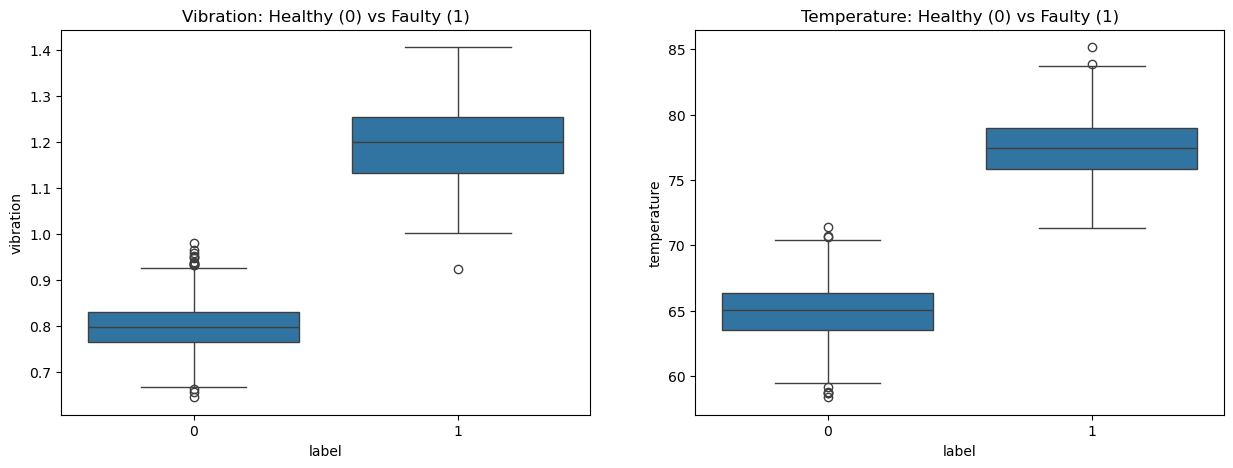

In [23]:
# Create a figure with two side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Vibration vs Machine State
# x is our target (0=Healthy, 1=Faulty), y is the sensor reading
sns.boxplot(x='label', y='vibration', data=Maint_encoded, ax=axes[0])
axes[0].set_title('Vibration: Healthy (0) vs Faulty (1)')

# Plot 2: Temperature vs Machine State
sns.boxplot(x='label', y='temperature', data=Maint_encoded, ax=axes[1])
axes[1].set_title('Temperature: Healthy (0) vs Faulty (1)')

plt.show()

## Model Training: Random Forest Classifier

We selected a **Random Forest Classifier** for this predictive maintenance pipeline due to three key advantages:

* **Robustness to Correlation:** Industrial sensors (such as vibration, temperature, and current) naturally correlate with one another. Unlike linear models that destabilize under multicollinearity, Random Forests are completely immune to feature correlation.
* **Zero Scaling Requirements:** The algorithm relies entirely on relative threshold splits rather than strict mathematical coefficients, meaning raw, unscaled sensor telemetry can be processed directly without data leakage risks.
* **Built-in Noise Reduction:** By aggregating 100 independent decision trees trained on randomized data subsets, the ensemble naturally dampens single-point sensor anomalies and outlier glitches.

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# 1. Separate Features (X) from the Target Label (y)
X = Maint_encoded.drop('label', axis=1)
y = Maint_encoded['label']

# 2. Split into 80% training data and 20% unseen test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and train the Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 4. Score the model on the test set
accuracy = rf_model.score(X_test, y_test)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 100.00%


## Model Interpretation: Feature Importances
To ensure the model relies on sound physical engineering principles rather than artifacts or noise, we extract and plot feature importances to see which sensors drove failure predictions.

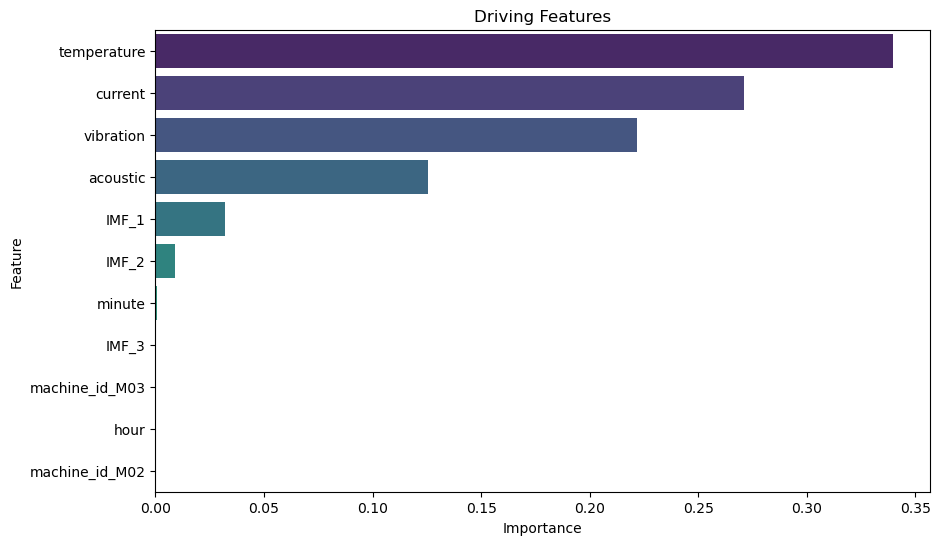

           Feature  Importance
2      temperature    0.339872
3          current    0.270820
0        vibration    0.221611
1         acoustic    0.125715
4            IMF_1    0.031844
5            IMF_2    0.008941
8           minute    0.000738
6            IMF_3    0.000345
10  machine_id_M03    0.000067
7             hour    0.000043
9   machine_id_M02    0.000004


In [25]:
importances = rf_model.feature_importances_
feature_names = X.columns

importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis', hue='Feature', legend=False)
plt.title('Driving Features')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

print(importance_df)